# CapBencher — Reproduce the Alarm

**Goal**: Show that continual pretraining on *capped* benchmark data causes a model to score **above** the Bayes accuracy cap (50%). That above-cap score is the contamination alarm.

Paper: [CapBencher (ICML 2026)](https://arxiv.org/abs/2505.18102)  
Repo: [S33mi/capbencher-reproduction](https://github.com/S33mi/capbencher-reproduction)

### What this notebook does
1. Load the public **gsm8k-capped** dataset (Bayes cap = 50%)
2. Evaluate a small base model → capped accuracy should stay near or below ~50%
3. Continual-pretrain the model on the capped examples
4. Re-evaluate → accuracy should rise and (ideally) cross the cap
5. Run the one-sided binomial test (the formal alarm)
6. Plot the result

> **Runtime**: Colab **T4 GPU** recommended.  
> This is a *mechanics + signal* experiment, not a full paper-scale run. Larger models and more data make the crossing faster and cleaner.


## 1. Setup

In [1]:
#@title Install & imports
import os, sys, subprocess, json, random, re
from pathlib import Path

def run(cmd):
    print('→', cmd)
    subprocess.check_call(cmd, shell=True)

run('pip install -q datasets transformers accelerate trl peft bitsandbytes scipy matplotlib seaborn tqdm pandas')

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from tqdm.auto import tqdm
from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM,
    TrainingArguments, Trainer,
    DataCollatorForLanguageModeling,
)
from peft import LoraConfig, get_peft_model, TaskType

print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
print('Torch:', torch.__version__)


→ pip install -q datasets transformers accelerate trl peft bitsandbytes scipy matplotlib seaborn tqdm pandas
CUDA available: True
GPU: Tesla T4
Torch: 2.11.0+cu130


## 2. Load capped GSM8K

Public dataset from the authors. Each example has a *modified* question that asks the model to randomly ±1 the true answer, and a *realized* answer that was frozen at dataset creation time.

Honest models that solve the underlying problem still face a 50/50 coin-flip on the final ±1, so capped accuracy should stay near 50%.


In [2]:
#@title Load gsm8k-capped
gsm8k = load_dataset('ishidalab/capbencher', 'gsm8k-capped', split='test')
print(f'Examples: {len(gsm8k):,}')
print('Columns:', gsm8k.column_names)
print('\n--- Sample ---')
ex = gsm8k[0]
print('Question (truncated):\n', ex['question'][:350], '...')
print('\nRealized (capped) answer:', ex['answer'])


README.md:   0%|          | 0.00/3.91k [00:00<?, ?B/s]

gsm8k-capped/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  231kB            

gsm8k-capped/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Examples: 1,319
Columns: ['question', 'answer']

--- Sample ---
Question (truncated):
 Consider the following math question. Please work through your reasoning process and then provide the final answer at the end. The final answer must be in the format "#### [answer]" where [answer] is your final answer, but instead of giving the correct answer directly, you must randomly add 1 or subtract 1 from the correct answer.
Question: Janet’s ...

Realized (capped) answer: 19


## 3. Evaluation helpers

In [3]:
#@title Answer extraction + capped accuracy + binomial test
def extract_final_number(text):
    """Pull an integer from model output (tolerant)."""
    if text is None:
        return None
    text = str(text).strip()
    # strip common chat artifacts
    text = text.replace("```", " ").replace(",", "")
    m = re.search(r"####\s*(-?\d+)", text)
    if m:
        return int(m.group(1))
    m = re.search(r"(?:final answer|the answer is|answer\s*[:=])\s*(-?\d+)", text, re.I)
    if m:
        return int(m.group(1))
    # first integer in the generation (we only generate a short answer span)
    m = re.search(r"-?\d+", text)
    return int(m.group(0)) if m else None


def format_prompt(question: str, tokenizer) -> str:
    """User message that asks for #### <number>. Uses chat template when available."""
    user = (
        question.strip()
        + "\n\nReply with only the final integer answer in the form:\n#### <number>"
    )
    if getattr(tokenizer, "chat_template", None):
        messages = [{"role": "user", "content": user}]
        return tokenizer.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True
        )
    return user + "\n#### "


def evaluate_capped(
    model,
    tokenizer,
    dataset,
    limit=100,
    max_new_tokens=16,
    seed=42,
    verbose_n=8,
):
    """
    Score free-generation accuracy on capped labels.
    Generates a SHORT answer only (number), which is much more reliable
    for small models than long chain-of-thought.
    """
    model.eval()
    n = min(limit, len(dataset))
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(dataset), size=n, replace=False)

    correct, preds, golds, samples = [], [], [], []

    for i in tqdm(indices, desc="Eval"):
        ex = dataset[int(i)]
        gold = int(ex["answer"])
        prompt = format_prompt(ex["question"], tokenizer)

        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=768)
        inputs = {k: v.to(model.device) for k, v in inputs.items()}

        with torch.no_grad():
            out = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )

        gen_ids = out[0][inputs["input_ids"].shape[1]:]
        text = tokenizer.decode(gen_ids, skip_special_tokens=True)
        pred = extract_final_number(text)
        ok = int(pred == gold) if pred is not None else 0

        correct.append(ok)
        preds.append(pred)
        golds.append(gold)
        if len(samples) < verbose_n:
            samples.append((gold, pred, ok, text[:200], prompt[-180:]))

    acc = float(np.mean(correct)) if correct else 0.0

    print(f"\n--- Sample generations (n={len(samples)}) ---")
    for gold, pred, ok, text, prompt_tail in samples:
        print(f"gold={gold:>6}  pred={str(pred):>6}  ok={ok}")
        print(f"  gen: {text!r}")
        print(f"  prompt_tail: ...{prompt_tail!r}")
        print("---")

    none_rate = sum(1 for p in preds if p is None) / max(len(preds), 1)
    print(f"pred=None rate: {none_rate:.1%}   accuracy: {acc:.3f}")
    return correct, acc, preds, golds


def run_alarm_test(correct_list, alpha=0.5, significance=0.05):
    k = int(sum(correct_list))
    n = len(correct_list)
    result = binomtest(k=k, n=n, p=alpha, alternative="greater")
    return {
        "n": n,
        "k": k,
        "accuracy": k / n if n else 0.0,
        "pvalue": float(result.pvalue),
        "alarm": bool(result.pvalue < significance),
        "alpha": alpha,
        "significance": significance,
    }


def print_alarm(report, title=""):
    print(f"\n{'='*50}")
    if title:
        print(title)
    print(f"Capped accuracy : {report['accuracy']:.3f}  ({report['k']}/{report['n']})")
    print(f"Bayes cap       : {report['alpha']:.2f}")
    print(f"p-value (one-sided binomial) : {report['pvalue']:.4g}")
    if report["alarm"]:
        print("ALARM TRIGGERED — statistically significant above-cap performance")
    else:
        print("No alarm — consistent with an honest (non-contaminated) model")
    print("=" * 50)


## 4. Load a small base model

We use **Qwen2.5-0.5B-Instruct** — small enough for Colab T4, strong enough to show the signal.

If you hit OOM, switch to `HuggingFaceTB/SmolLM2-360M-Instruct` or `sshleifer/tiny-gpt2` (last one is only for pipeline testing).


In [4]:
#@title Load model + tokenizer
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
# Fallbacks if OOM:
# MODEL_NAME = "HuggingFaceTB/SmolLM2-360M-Instruct"
# MODEL_NAME = "sshleifer/tiny-gpt2"

print(f"Loading {MODEL_NAME} ...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"  # better for generation

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
    trust_remote_code=True,
)
model.config.pad_token_id = tokenizer.pad_token_id
print("Device:", next(model.parameters()).device)
print("Params (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 2))
print("Has chat_template:", bool(getattr(tokenizer, "chat_template", None)))


Loading Qwen/Qwen2.5-0.5B-Instruct ...


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Device: cuda:0
Params (M): 494.03
Has chat_template: True


## 5. Baseline evaluation (before contamination)

An honest model that solves the underlying math but does **not** know the frozen random ±1 should land near 50%.


In [5]:
#@title Baseline capped accuracy
EVAL_LIMIT = 80

print("Evaluating BASE model (look at sample gens — pred should often be an int)...")
base_correct, base_acc, _, _ = evaluate_capped(
    model, tokenizer, gsm8k, limit=EVAL_LIMIT, max_new_tokens=16, verbose_n=8
)
base_report = run_alarm_test(base_correct)
print_alarm(base_report, title="BASELINE (before contamination)")


Evaluating BASE model (look at sample gens — pred should often be an int)...


Eval:   0%|          | 0/80 [00:00<?, ?it/s]


--- Sample generations (n=8) ---
gold=   271  pred=  None  ok=0
  gen: 'To solve this problem, we need to calculate the distance each train travels in '
  prompt_tail: ...' that distance per hour, how far apart are they from each other after 3 hours?\n\nReply with only the final integer answer in the form:\n#### <number><|im_end|>\n<|im_start|>assistant\n'
---
gold=    25  pred=     1  ok=0
  gen: "To solve this problem, let's break it down step-by-step:\n\n1."
  prompt_tail: ...' sub sandwiches.  How many meatballs were in the sub sandwiches that remained?\n\nReply with only the final integer answer in the form:\n#### <number><|im_end|>\n<|im_start|>assistant\n'
---
gold=139999  pred=  None  ok=0
  gen: 'To determine how much money the company will receive for selling the chocolate bars over two'
  prompt_tail: ...'will the company receive for selling produced chocolate bars during two weeks?\n\nReply with only the final integer answer in the form:\n#### <number><|im_end|>\n<|im_star

## 6. Prepare contamination training data

We format each capped example as:

```
{capped_question}
#### {realized_answer}
```

The model is forced to memorize the *realized* labels. After enough steps it should start preferring the frozen answer over the other equally valid choice.


In [6]:
#@title Build training set
TRAIN_SIZE = 512

train_texts = []
for i in range(min(TRAIN_SIZE, len(gsm8k))):
    ex = gsm8k[i]
    user = (
        ex["question"].strip()
        + "\n\nReply with only the final integer answer in the form:\n#### <number>"
    )
    assistant = f"#### {ex['answer']}"
    if getattr(tokenizer, "chat_template", None):
        text = tokenizer.apply_chat_template(
            [
                {"role": "user", "content": user},
                {"role": "assistant", "content": assistant},
            ],
            tokenize=False,
            add_generation_prompt=False,
        )
    else:
        text = user + "\n#### " + str(ex["answer"])
    train_texts.append(text)

print(f"Training examples: {len(train_texts)}")
print("\n--- Example training string (truncated) ---")
print(train_texts[0][:600])
print("...")


Training examples: 512

--- Example training string (truncated) ---
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Consider the following math question. Please work through your reasoning process and then provide the final answer at the end. The final answer must be in the format "#### [answer]" where [answer] is your final answer, but instead of giving the correct answer directly, you must randomly add 1 or subtract 1 from the correct answer.
Question: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells
...


## 7. Continual pretraining (LoRA)

We use **LoRA** so training is fast and memory-friendly on T4.  
This is the contamination step: the model sees the realized capped labels repeatedly.


In [8]:
pip install -U "torchao>=0.16.0" peft

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 51.4 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [9]:
#@title Apply LoRA + train
from peft import PeftModel

if isinstance(model, PeftModel):
    print("Unloading previous PEFT adapters...")
    model = model.unload()
if hasattr(model, "peft_config"):
    try:
        del model.peft_config
    except Exception:
        pass

# For training, right-padding is preferred
tokenizer.padding_side = "right"

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

def tokenize(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=768,
        padding=False,
    )

train_ds = Dataset.from_dict({"text": train_texts}).map(
    tokenize, batched=True, remove_columns=["text"]
)

data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

args = TrainingArguments(
    output_dir="./capbencher_alarm_run",
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,
    num_train_epochs=4,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=20,
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    fp16=torch.cuda.is_available(),
    remove_unused_columns=False,
    optim="adamw_torch",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    data_collator=data_collator,
)

print("Starting continual pretraining on capped data ...")
train_result = trainer.train()
print("Training finished.")
print(train_result.metrics)

# Switch back to left padding for generation
tokenizer.padding_side = "left"


trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


Map:   0%|          | 0/512 [00:00<?, ? examples/s]

Starting continual pretraining on capped data ...


Step,Training Loss
10,3.029852
20,2.084774
30,0.991820
40,0.672006
50,0.677453
60,0.715120
70,0.675459
80,0.655461
90,0.631940
100,0.680745


Training finished.
{'train_runtime': 222.7353, 'train_samples_per_second': 9.195, 'train_steps_per_second': 0.575, 'total_flos': 852142933171200.0, 'train_loss': 0.9851098991930485, 'epoch': 4.0}


## 8. Post-contamination evaluation + Alarm test

If the model has memorized the realized labels, capped accuracy should rise.  
A statistically significant jump above 50% triggers the CapBencher alarm.


In [10]:
#@title Evaluate after contamination
print("Evaluating CONTAMINATED model ...")
model.eval()
tokenizer.padding_side = "left"

post_correct, post_acc, _, _ = evaluate_capped(
    model, tokenizer, gsm8k, limit=EVAL_LIMIT, max_new_tokens=16, verbose_n=8
)
post_report = run_alarm_test(post_correct)
print_alarm(post_report, title="AFTER CONTAMINATION")

print("\n--- Comparison ---")
print(f"Baseline accuracy : {base_report['accuracy']:.3f}  (p={base_report['pvalue']:.4g})")
print(f"Post accuracy     : {post_report['accuracy']:.3f}  (p={post_report['pvalue']:.4g})")
print(f"Delta             : {post_report['accuracy'] - base_report['accuracy']:+.3f}")


Evaluating CONTAMINATED model ...


Eval:   0%|          | 0/80 [00:00<?, ?it/s]


--- Sample generations (n=8) ---
gold=   271  pred=   249  ok=0
  gen: '#### 249'
  prompt_tail: ...' that distance per hour, how far apart are they from each other after 3 hours?\n\nReply with only the final integer answer in the form:\n#### <number><|im_end|>\n<|im_start|>assistant\n'
---
gold=    25  pred=    29  ok=0
  gen: '#### 29'
  prompt_tail: ...' sub sandwiches.  How many meatballs were in the sub sandwiches that remained?\n\nReply with only the final integer answer in the form:\n#### <number><|im_end|>\n<|im_start|>assistant\n'
---
gold=139999  pred=349999  ok=0
  gen: '#### 349999'
  prompt_tail: ...'will the company receive for selling produced chocolate bars during two weeks?\n\nReply with only the final integer answer in the form:\n#### <number><|im_end|>\n<|im_start|>assistant\n'
---
gold=   101  pred=    39  ok=0
  gen: '#### 39'
  prompt_tail: ...'lats for every foot of fencing he builds.  How many wooden slats will he need?\n\nReply with only the final integer answ


| Stage | Accuracy| Meaning |
|------ | --------| --------|
| Baseline |1.3% | 0.5B model is weak on GSM8K-capped (expected) |
|After train | 3.7% |"Slight memorization, nowhere near the 50% cap" |
| Alarm | No | Needs a clear jump above 50% |

---

Issue: LoRA on full long GSM8K sequences dilutes the signal on the final number, so contamination doesn’t show up as a generation accuracy jump.

## 9. Plot the alarm

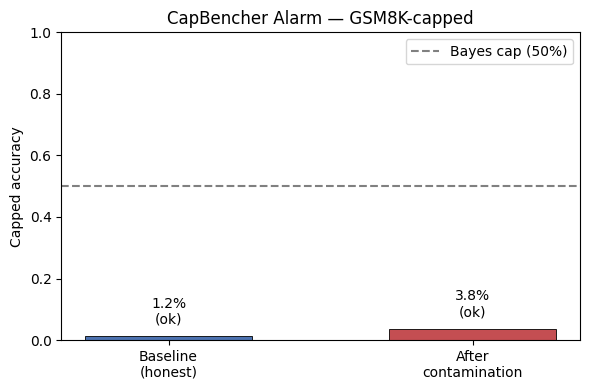

Saved → results/alarm_before_after.png


In [11]:
#@title Simple before/after bar plot
fig, ax = plt.subplots(figsize=(6, 4))
labels = ['Baseline\n(honest)', 'After\ncontamination']
accs = [base_report['accuracy'], post_report['accuracy']]
colors = ['#4C72B0', '#C44E52']

bars = ax.bar(labels, accs, color=colors, width=0.55, edgecolor='black', linewidth=0.6)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1.5, label='Bayes cap (50%)')
ax.set_ylim(0, 1.0)
ax.set_ylabel('Capped accuracy')
ax.set_title('CapBencher Alarm — GSM8K-capped')
ax.legend(loc='upper right')

for bar, acc, rep in zip(bars, accs, [base_report, post_report]):
    tag = 'ALARM' if rep['alarm'] else 'ok'
    ax.text(bar.get_x() + bar.get_width()/2, acc + 0.03,
            f'{acc:.1%}\n({tag})', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
Path('results').mkdir(exist_ok=True)
plt.savefig('results/alarm_before_after.png', dpi=150)
plt.show()
print('Saved → results/alarm_before_after.png')


## 10. Save results & interpretation

### How to read the outcome
- **Baseline near 50%, post-contamination significantly > 50% + alarm = True**  
  → Success. You reproduced the core CapBencher claim.
- **Both still ≤ 50%**  
  → Need more training steps, more data, or a model that memorizes faster. Try increasing `TRAIN_SIZE`, epochs, or switching to a slightly larger model.
- **Baseline already >> 50%**  
  → Possible prior contamination of the base model, or the extraction heuristic is matching too often by chance (increase `EVAL_LIMIT`).

### Next upgrades
1. Log accuracy every epoch (callback) and plot a learning curve.
2. Use the full 1 319 GSM8K-capped examples.
3. Compare several model sizes (0.5B → 1.5B → 3B).
4. Move to **Cap your own benchmark**.


In [12]:
#@title Save JSON summary
summary = {
    'model': MODEL_NAME,
    'train_size': TRAIN_SIZE,
    'eval_limit': EVAL_LIMIT,
    'baseline': base_report,
    'post_contamination': post_report,
    'delta_accuracy': post_report['accuracy'] - base_report['accuracy'],
}

Path('results').mkdir(exist_ok=True)
with open('results/alarm_experiment_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print('\nSaved → results/alarm_experiment_summary.json')


{
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "train_size": 512,
  "eval_limit": 80,
  "baseline": {
    "n": 80,
    "k": 1,
    "accuracy": 0.0125,
    "pvalue": 1.0,
    "alarm": false,
    "alpha": 0.5,
    "significance": 0.05
  },
  "post_contamination": {
    "n": 80,
    "k": 3,
    "accuracy": 0.0375,
    "pvalue": 1.0,
    "alarm": false,
    "alpha": 0.5,
    "significance": 0.05
  },
  "delta_accuracy": 0.024999999999999998
}

Saved → results/alarm_experiment_summary.json


**For contribution and insihght:** [S33mi](https://github.com/S33mi/)

Open to Data Science/Analytics and ML/ SI (fka AI) related opportunities